# 07 – Carte interactive du risque

**Objectif :** rendre le modèle **visible et utilisable**. Un tableau de 130 000 probabilités ne parle à personne ; une carte où les communes à risque s'allument en rouge, tout le monde la comprend.

Au programme :
1. une lecture « **prévu vs réalisé** » au niveau du département (ton terrain de jeu en prévision de demande !) ;
2. une leçon sur la **calibration** ;
3. la **carte du risque d'un jour donné**, avec les feux réels par-dessus ;
4. un **atlas du risque estival** moyen par commune.

## Leçon 1 – Une carte avec folium

**folium** est une bibliothèque Python qui fabrique des cartes web interactives (zoom, survol, clic). Sous le capot, elle génère une page HTML utilisant Leaflet, la même technologie que beaucoup de sites de cartographie.

Pour colorier des communes, il faut leurs **contours** (des polygones = listes de points GPS). Le format standard pour ça s'appelle le **GeoJSON** : du JSON avec des géométries. L'API geo.api.gouv.fr nous le fournit directement.

In [1]:
import json
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import folium
import branca.colormap as cm

predictions = pd.read_csv("../data/processed/predictions_test.csv", dtype={"code": str}, parse_dates=["jour"])
communes = pd.read_csv("../data/processed/communes_13.csv", dtype={"code": str})
print(predictions.shape)
predictions.head()

(130424, 5)


,code,jour,feu,proba_modele,score_baseline
0,13001,2023-01-01,0,0.001855,0.004608
1,13001,2023-01-02,0,0.000811,0.004608
2,13001,2023-01-03,0,0.000628,0.004608
3,13001,2023-01-04,0,0.000697,0.004608
4,13001,2023-01-05,0,0.001347,0.004608


## Étape 1 – Prévu vs réalisé à l'échelle du département

### Leçon 2 – Additionner des probabilités
Si une commune a 10 % de risque et une autre 30 %, on « attend » 0,1 + 0,3 = **0,4 feu** en tout ce jour-là. En additionnant les probabilités des 119 communes, on obtient le **nombre de feux attendu** dans le département, jour par jour. On peut alors comparer à ce qui s'est réellement passé – exactement comme une prévision de ventes face au réalisé.

In [2]:
par_jour = predictions.groupby("jour")[["proba_modele", "feu"]].sum()
par_jour.columns = ["feux_prevus", "feux_reels"]

print("Total prévu  :", round(par_jour["feux_prevus"].sum()))
print("Total réel   :", par_jour["feux_reels"].sum())
par_jour.resample("YE").sum().round(0)

Total prévu  : 920
Total réel   : 728


,feux_prevus,feux_reels
jour,,
2023-12-31,347.0,269
2024-12-31,257.0,207
2025-12-31,316.0,252


`resample("YE")` regroupe une série de dates par période – ici par année (*Year End*). `"ME"` ferait par mois, `"W"` par semaine. Très utile en prévision de demande !

### Leçon 3 – La calibration
Le modèle prévoit environ **920 feux**, il y en a eu **728** : il **surestime d'environ 25 %**, et ce chaque année.

Un modèle est **bien calibré** quand ses probabilités correspondent aux fréquences réelles (« parmi les jours où il dit 10 %, il y a bien un feu 1 fois sur 10 »).

Pourquoi ce biais ? Le modèle final a été entraîné sur 2016-2022, qui contient **2022, l'année record**. Il a appris un niveau de risque moyen un peu plus élevé que celui de 2023-2025.

**Est-ce grave ?** Ça dépend de l'usage :
- pour **classer** les communes et les jours (qui surveiller en priorité ?) → non : la PR-AUC ne dépend que de l'ordre, et le modèle classe bien ;
- pour **annoncer un nombre** (« on attend 5 feux demain ») → oui, il faudrait **recalibrer** (corriger les probabilités). C'est une piste d'amélioration à noter dans le README.

> En prévision de demande, c'est la différence entre un bon **mix** (bien répartir entre produits) et un bon **niveau** (le bon total) : deux qualités distinctes.

Regardons l'été 2023 jour par jour :

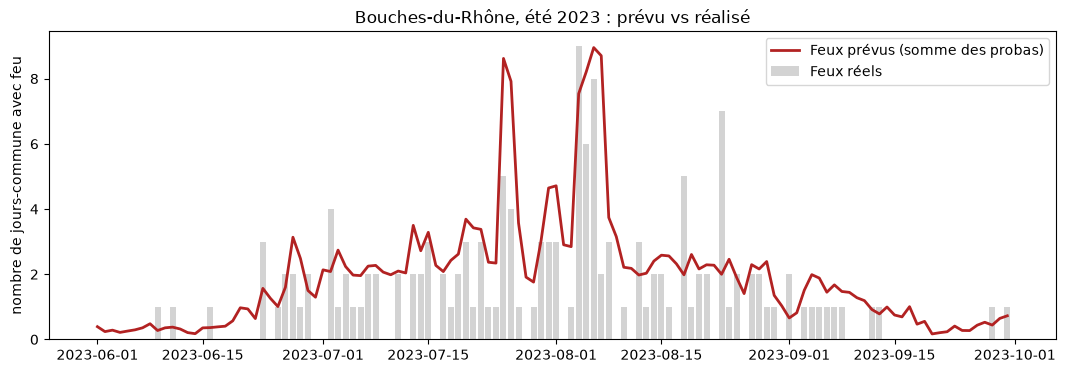

In [3]:
ete = par_jour.loc["2023-06-01":"2023-09-30"]

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(ete.index, ete["feux_reels"], color="lightgrey", label="Feux réels")
ax.plot(ete.index, ete["feux_prevus"], color="firebrick", linewidth=2, label="Feux prévus (somme des probas)")
ax.set_title("Bouches-du-Rhône, été 2023 : prévu vs réalisé")
ax.set_ylabel("nombre de jours-commune avec feu")
ax.legend()
plt.show()

`.loc["2023-06-01":"2023-09-30"]` sélectionne une plage de dates (possible parce que les dates sont l'**index** du tableau).

**Lecture :** la courbe rouge suit bien les **épisodes** de feux (les vagues de chaleur / mistral de fin juillet et début août) et reste basse les jours calmes. Elle ne peut pas prédire le chiffre exact d'un jour donné – un départ de feu dépend aussi d'une étincelle humaine imprévisible – mais elle détecte les **périodes dangereuses**.

## Étape 2 – Télécharger les contours des communes

On les sauvegarde dans `data/raw/` pour ne pas les retélécharger à chaque fois (même logique que le cache météo).

`Path(...)` est la façon moderne de manipuler des chemins de fichiers ; `.exists()` teste si le fichier est déjà là.

In [4]:
chemin_geojson = Path("../data/raw/communes_13.geojson")

if not chemin_geojson.exists():
    url = "https://geo.api.gouv.fr/departements/13/communes?fields=nom,code&format=geojson&geometry=contour"
    chemin_geojson.write_text(requests.get(url).text, encoding="utf-8")

contours = json.loads(chemin_geojson.read_text(encoding="utf-8"))
print(len(contours["features"]), "communes")
contours["features"][0]["properties"]

119 communes


{'nom': 'Aix-en-Provence', 'code': '13001'}

Un GeoJSON est un grand dictionnaire : la clé `features` contient une liste, avec pour chaque commune ses `properties` (nom, code) et sa `geometry` (le polygone).

## Étape 3 – La carte du risque d'un jour donné

On choisit un jour – le **6 août 2023**, le jour que le modèle jugeait le plus dangereux de toute la période de test – et on construit la carte en 4 temps :

1. **les données du jour** : un dictionnaire `{code commune: probabilité}` ;
2. **une échelle de couleurs** (`LinearColormap`) : du jaune (faible) au rouge foncé (élevé) ;
3. **les communes coloriées** (`folium.GeoJson`), avec une `style_function` : une petite fonction appelée pour **chaque** commune, qui renvoie sa couleur ;
4. **les feux réels** par-dessus : un rond noir au centre des communes qui ont vraiment brûlé ce jour-là.

On emballe tout ça dans une **fonction** `carte_du_jour(date)` pour pouvoir refaire la carte de n'importe quel jour en une ligne.

In [5]:
def carte_du_jour(date):
    # 1. les données du jour
    du_jour = predictions[predictions["jour"] == date].merge(communes, on="code")
    risque = dict(zip(du_jour["code"], du_jour["proba_modele"]))

    # 2. l'échelle de couleurs (fixe, pour comparer les jours entre eux)
    echelle = cm.LinearColormap(["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c", "#800026"],
                                vmin=0, vmax=0.3, caption="Probabilité de départ de feu")

    # 3. la carte et les communes coloriées
    carte = folium.Map(location=[43.5, 5.1], zoom_start=9, tiles="OpenStreetMap")

    for f in contours["features"]:               # on écrit la probabilité dans chaque commune
        p = risque.get(f["properties"]["code"], 0)
        f["properties"]["risque"] = f"{p:.1%}"

    folium.GeoJson(
        contours,
        style_function=lambda f: {
            "fillColor": echelle(min(risque.get(f["properties"]["code"], 0), 0.3)),
            "color": "white", "weight": 0.5, "fillOpacity": 0.75,
        },
        tooltip=folium.GeoJsonTooltip(fields=["nom", "risque"], aliases=["Commune", "Risque"]),
    ).add_to(carte)
    echelle.add_to(carte)

    # 4. les feux réels
    for _, row in du_jour[du_jour["feu"] == 1].iterrows():
        folium.CircleMarker(
            location=[row["lat"], row["lon"]], radius=6,
            color="black", fill=True, fill_color="black",
            tooltip=f"🔥 Feu réel – {row['nom']}",
        ).add_to(carte)

    print(f"{date} : {du_jour['feu'].sum()} feux réels, {du_jour['proba_modele'].sum():.1f} prévus")
    return carte

carte = carte_du_jour("2023-08-06")
carte

2023-08-06 : 8 feux réels, 9.0 prévus


**Explore la carte :** zoome, survole les communes (le nom et le risque s'affichent). Les ronds noirs (feux réels) tombent-ils dans les zones rouges ?

Quelques nouveautés Python :
- `dict(zip(a, b))` : `zip` associe les éléments deux à deux, `dict` en fait un dictionnaire `{a1: b1, a2: b2, …}` ;
- `risque.get(code, 0)` : lit la valeur du dictionnaire, et renvoie 0 si le code est absent (au lieu de planter) ;
- `min(p, 0.3)` : on plafonne à 30 % pour que l'échelle de couleurs reste lisible ;
- l'**échelle est fixe** (0 à 30 %) : ainsi un jour calme apparaîtra vraiment jaune, et on peut comparer deux cartes entre elles.

## Étape 4 – Sauvegarder la carte

Une carte folium est une **page web** autonome : on peut l'ouvrir dans n'importe quel navigateur, l'envoyer par mail… ou la mettre sur GitHub pour ton portfolio.

In [6]:
dossier = Path("../outputs")
dossier.mkdir(exist_ok=True)   # crée le dossier s'il n'existe pas (comme mkdir -p)

carte.save(dossier / "carte_risque_2023-08-06.html")
print("Carte enregistrée dans", dossier.resolve())

Carte enregistrée dans /Users/duvalthomas/ml-projets/incendies/outputs


`dossier / "fichier.html"` : avec `Path`, l'opérateur `/` **assemble des chemins** (ça marche sur Mac comme sur Windows). Double-clique sur le fichier dans le Finder pour l'ouvrir dans ton navigateur.

**À toi de jouer :** fais la carte d'un jour **calme** (par exemple `"2024-02-10"`), puis celle du **16 juillet 2025** (le jour avec le plus de feux réels : 11). Compare : le modèle les avait-il vus venir ?

### Correction de l'exercice

⚠️ **Le piège :** une cellule n'affiche automatiquement que le résultat de sa **dernière ligne**. Si on écrit deux `carte_du_jour(...)` dans la même cellule, seule la 2ᵉ carte s'affiche. On fait donc **une cellule par carte**.

**Carte 1 – un jour calme (10 février 2024)**

In [7]:
carte_calme = carte_du_jour("2024-02-10")
carte_calme

2024-02-10 : 0 feux réels, 0.0 prévus


Tout le département est jaune pâle : le risque maximum ce jour-là est d'environ 0,4 %, et il n'y a eu aucun feu. Le modèle sait aussi dire « **rien à signaler** » – c'est tout aussi important qu'une alerte.

**Carte 2 – le jour record (16 juillet 2025, 11 feux réels)**

In [8]:
carte_record = carte_du_jour("2025-07-16")
carte_record

2025-07-16 : 11 feux réels, 5.8 prévus


On peut aussi lister les communes qui ont brûlé et le risque que le modèle leur donnait :

In [9]:
record = predictions[predictions["jour"] == "2025-07-16"].merge(communes[["code", "nom"]], on="code")
record["rang"] = record["proba_modele"].rank(ascending=False).astype(int)   # 1 = commune la plus risquée ce jour-là
record[record["feu"] == 1].sort_values("proba_modele", ascending=False)[["nom", "proba_modele", "rang"]]

,nom,proba_modele,rang
55,Martigues,0.329824,1
54,Marseille,0.323404,2
70,Les Pennes-Mirabeau,0.179564,9
76,Port-de-Bouc,0.121348,11
87,Le Rove,0.119500,13
4,Aubagne,0.116716,14
40,Gardanne,0.100186,15
43,Grans,0.071903,24
84,Roquefort-la-Bédoule,0.048082,36
101,Saint-Victoret,0.031164,54


`rank(ascending=False)` numérote les communes de la plus risquée (1) à la moins risquée (119).

**Le modèle les avait-il vus venir ?**
- **Le niveau, en partie :** il attendait environ 6 feux, il y en a eu 11. Il avait bien identifié une journée dangereuse (risque moyen ≈ 5 %, contre 0,03 % le 10 février), mais a sous-estimé son ampleur – alors qu'en moyenne il surestime (cf. calibration). Les journées extrêmes restent difficiles à chiffrer.
- **La géographie, oui :** Martigues et Marseille, les deux communes qui ont brûlé avec les plus hauts risques, sont dans le **top 2** du jour (environ 33 %). La plupart des autres communes touchées (Les Pennes-Mirabeau, Port-de-Bouc, Le Rove, Aubagne, Gardanne) sont aussi dans les zones orange/rouges.

Sauvegarde la carte du record pour le README :

In [10]:
carte_record.save(dossier / "carte_risque_2025-07-16.html")

## Étape 5 – L'atlas du risque estival

Dernière carte : le risque **moyen** de chaque commune sur les étés (juillet-août) 2023-2025. C'est une vue « stratégique » : où placer en priorité les moyens de surveillance sur toute la saison ?

`isin([7, 8])` garde les lignes dont le mois est 7 **ou** 8.

In [11]:
ete_test = predictions[predictions["jour"].dt.month.isin([7, 8])]
risque_ete = ete_test.groupby("code")["proba_modele"].mean()
feux_ete = ete_test.groupby("code")["feu"].sum()

echelle_ete = cm.LinearColormap(["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c", "#800026"],
                                vmin=0, vmax=risque_ete.max(),
                                caption="Risque moyen d'un jour d'été (juillet-août 2023-2025)")

for f in contours["features"]:
    code_c = f["properties"]["code"]
    f["properties"]["risque_ete"] = f"{risque_ete.get(code_c, 0):.1%}"
    f["properties"]["feux_ete"] = int(feux_ete.get(code_c, 0))

atlas = folium.Map(location=[43.5, 5.1], zoom_start=9, tiles="OpenStreetMap")
folium.GeoJson(
    contours,
    style_function=lambda f: {
        "fillColor": echelle_ete(risque_ete.get(f["properties"]["code"], 0)),
        "color": "white", "weight": 0.5, "fillOpacity": 0.75,
    },
    tooltip=folium.GeoJsonTooltip(fields=["nom", "risque_ete", "feux_ete"],
                                  aliases=["Commune", "Risque moyen", "Jours avec feu (étés 23-25)"]),
).add_to(atlas)
echelle_ete.add_to(atlas)

atlas.save(dossier / "atlas_risque_ete.html")
atlas

**Lecture :** l'axe **Marseille – étang de Berre – Martigues – Istres** et **Aix** ressortent nettement ; la **plaine agricole du nord** (Maillane, Rognonas, Cabannes… vers la Durance) reste pâle : des cultures irriguées, peu de garrigue. En survolant, compare le risque moyen et le nombre réel de jours avec feu : les communes les plus rouges sont-elles bien celles qui ont le plus brûlé ? (Réponse chiffrée : la corrélation de rang entre les deux est d'environ 0,78 – très forte.)

## Récap du notebook

1. **Somme des probabilités = nombre de feux attendu** → comparaison prévu / réalisé, comme en prévision de demande.
2. **Calibration** : le modèle classe bien (PR-AUC) mais **surestime le niveau d'environ 25 %** (effet 2022 dans l'entraînement). Piste : recalibrer.
3. **folium** : `Map` + `GeoJson` (contours coloriés via `style_function`) + `CircleMarker` (points) + `tooltip` (survol) → page HTML autonome.
4. Les cartes sont dans `outputs/` : prêtes pour le README.

**Prochaine étape (08) :** la **carte de scénarios 2027**, avec des curseurs (scénario météo, semaine, seuil).